# 28. Text Classification Evaluation

## Overview
Model evaluation measures how well a text classifier generalizes to unseen data. Accuracy is useful, but precision, recall, F1-score, class imbalance, and the confusion matrix provide a more complete picture.

This notebook compares evaluation metrics and demonstrates stratified cross-validation for a TF-IDF classification pipeline.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

## 2. Prepare labeled documents

This synthetic dataset demonstrates metric calculations. It is too small to support strong claims about generalization.

In [2]:
data = [
    ("excellent product and helpful support", "positive"),
    ("great quality and fast delivery", "positive"),
    ("I really like this useful product", "positive"),
    ("wonderful service and friendly staff", "positive"),
    ("the purchase was fantastic", "positive"),
    ("very good quality", "positive"),
    ("terrible product and poor quality", "negative"),
    ("the service was slow and disappointing", "negative"),
    ("I regret buying this item", "negative"),
    ("the product broke immediately", "negative"),
    ("unhelpful support and frustrating experience", "negative"),
    ("this was a bad purchase", "negative"),
    ("the box contains a charger", "neutral"),
    ("the item is available in blue", "neutral"),
    ("the report was published on Friday", "neutral"),
    ("the device has three buttons", "neutral"),
    ("the package arrived at noon", "neutral"),
    ("the manual contains ten pages", "neutral"),
    ("the product is good but delivery was slow", "mixed"),
    ("useful features but poor battery life", "mixed"),
    ("friendly staff but a long waiting time", "mixed"),
    ("good design with disappointing performance", "mixed"),
]

df = pd.DataFrame(data, columns=["text", "label"])
display(df.groupby("label").size().rename("count").to_frame())

,count
label,
mixed,4
negative,6
neutral,6
positive,6


## 3. Split into training and test sets

Use stratification so each class is represented proportionally in both sets when possible.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"],
    df["label"],
    test_size=0.36,
    random_state=7,
    stratify=df["label"],
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000, random_state=7)),
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 4. Calculate common metrics

For multiclass classification, `macro` averaging calculates each class's metric separately and then gives all classes equal weight. `weighted` averaging weights each class by its support.

In [4]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "F1 (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
}

metrics_df = pd.DataFrame(
    [{"metric": name, "score": score} for name, score in metrics.items()]
)
display(metrics_df.round(3))

,metric,score
0,Accuracy,0.375
1,Precision (macro),0.312
2,Recall (macro),0.375
3,F1 (macro),0.333
4,F1 (weighted),0.333


## 5. Read the classification report

The report includes precision, recall, F1-score, and support for each class.

In [5]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

       mixed       0.00      0.00      0.00         2
    negative       0.00      0.00      0.00         2
     neutral       1.00      1.00      1.00         2
    positive       0.25      0.50      0.33         2

    accuracy                           0.38         8
   macro avg       0.31      0.38      0.33         8
weighted avg       0.31      0.38      0.33         8



## 6. Inspect the confusion matrix

Rows represent true labels and columns represent predicted labels.

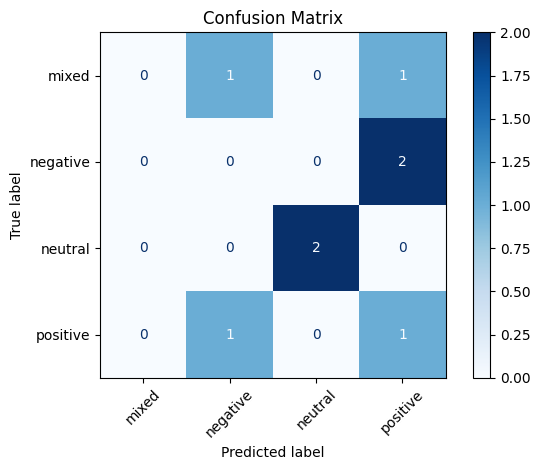

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45,
    cmap="Blues",
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Use stratified cross-validation

Cross-validation evaluates the model across several training/validation splits. It is useful for estimating variability when data is limited, although a larger dataset is preferable.

In [9]:
import warnings
warnings.filterwarnings('ignore')

class_counts = df["label"].value_counts()
n_splits = min(3, int(class_counts.min()))

if n_splits >= 2:
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=7)
    scoring = {
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro",
    }

    cv_results = cross_validate(
        model,
        df["text"],
        df["label"],
        cv=cv,
        scoring=scoring,
        error_score="raise",
    )

    summary = pd.DataFrame({
        "metric": list(scoring.keys()),
        "mean": [cv_results[f"test_{name}"].mean() for name in scoring],
        "std": [cv_results[f"test_{name}"].std() for name in scoring],
    })
    display(summary.round(3))
else:
    print("Not enough examples in every class for stratified cross-validation.")

,metric,mean,std
0,accuracy,0.411,0.025
1,precision_macro,0.333,0.085
2,recall_macro,0.417,0.059
3,f1_macro,0.364,0.072


## Interpretation and limitations

- Accuracy can be misleading when class frequencies are uneven.
- Macro F1 treats every class equally and is useful when minority classes matter.
- Weighted F1 accounts for class support but may hide poor performance on rare classes.
- Keep a final test set separate from model selection and cross-validation.
- Scores on a small synthetic dataset are illustrative only.

## Summary

Use multiple metrics to understand classification behavior. For multiclass tasks, inspect per-class results and choose averaging strategies that match the project's evaluation objective.